<a href="https://colab.research.google.com/github/Arjunanand717/Deep-learing-/blob/main/EXP8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

- **Name:** [ARJUN]
- **Roll Number:** [24BAD401
]

## PART A: DATASET PREPARATION AND PREPROCESSING
Perform the following tasks:
- Load the MNIST handwritten digit dataset using TensorFlow/Keras.
- Explore the dataset and check the number of training and testing images and their dimensions.
- Normalize pixel values to the range [0, 1].
- Flatten each 28x28 image into a 784-dimensional input vector.

In [1]:
%%bash
pip install -q python-docx

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, losses
from tensorflow.keras.models import Model
from sklearn.decomposition import PCA

# 1. Load and preprocess MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize the dataset
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Flatten the images (28x28 -> 784)
x_train_flat = x_train.reshape((len(x_train), np.prod(x_train.shape[1:])))
x_test_flat = x_test.reshape((len(x_test), np.prod(x_test.shape[1:])))

print(f"Training data shape: {x_train_flat.shape}")
print(f"Test data shape: {x_test_flat.shape}")

Training data shape: (60000, 784)
Test data shape: (10000, 784)


## PART B: IMPLEMENTING THE ENCODER AND DECODER
Perform the following tasks:
- Define the input layer with 784 features.
- Build the encoder using Dense layers to map inputs to 32 latent features.
- Build the decoder to map the latent representation back to 784 outputs.
- Combine them into a single Autoencoder model.

In [11]:
# 2. Define the Autoencoder Architecture
latent_dim = 32  # Compression factor of ~24.5 (784 to 32)

class Autoencoder(Model):
    def __init__(self, latent_dim):
        super(Autoencoder, self).__init__()
        self.latent_dim = latent_dim
        # Encoder
        self.encoder = tf.keras.Sequential([
            layers.Dense(128, activation='relu'),
            layers.Dense(64, activation='relu'),
            layers.Dense(latent_dim, activation='relu'),
        ])
        # Decoder
        self.decoder = tf.keras.Sequential([
            layers.Dense(64, activation='relu'),
            layers.Dense(128, activation='relu'),
            layers.Dense(784, activation='sigmoid')
        ])

    def call(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

autoencoder = Autoencoder(latent_dim)
autoencoder.compile(optimizer='adam', loss=losses.MeanSquaredError())

# 3. Train the Autoencoder
history = autoencoder.fit(x_train_flat, x_train_flat,
                epochs=15,
                batch_size=256,
                shuffle=True,
                validation_data=(x_test_flat, x_test_flat))

Epoch 1/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.0647 - val_loss: 0.0387
Epoch 2/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - loss: 0.0334 - val_loss: 0.0283
Epoch 3/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0255 - val_loss: 0.0229
Epoch 4/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0219 - val_loss: 0.0204
Epoch 5/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0200 - val_loss: 0.0188
Epoch 6/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.0186 - val_loss: 0.0176
Epoch 7/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0174 - val_loss: 0.0164
Epoch 8/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0164 - val_loss: 0.0157
Epoch 9/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 0.0157 - val_loss: 0.0150
Epoch 10/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0151 - val_loss: 0.0145
Epoch 11/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.0146 - val_loss: 0.0140
Epoch 12/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 

## PART C: COMPILING AND TRAINING THE AUTOENCODER
Perform the following tasks:
- Compile the model with the Adam optimizer and Mean Squared Error loss.
- Train the model using the input images as both inputs and targets.
- Plot the training and validation loss curves.

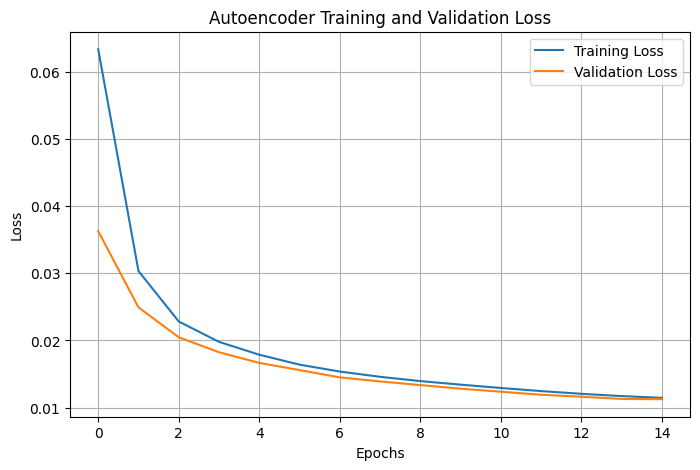

In [7]:
# 4. Plot Training & Validation Loss
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Autoencoder Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

## PART D: DIMENSIONALITY REDUCTION, FEATURE LEARNING AND RECONSTRUCTION
Perform the following tasks:
- Use the trained encoder to convert test images into lower-dimensional latent feature vectors.
- Reconstruct and compare original and reconstructed images.
- Project the 32-dimensional latent space to 2D using PCA for visualization.

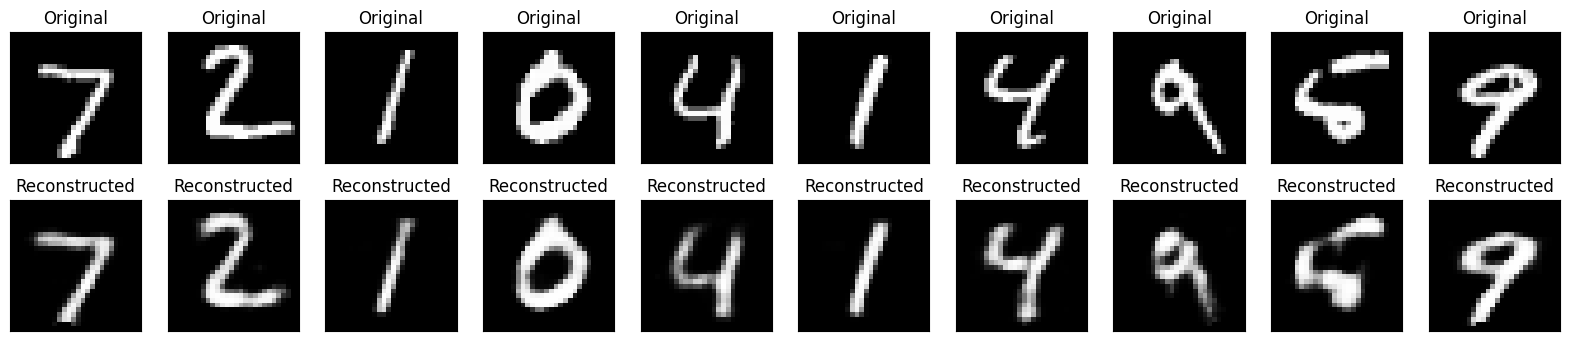

In [8]:
# 5. Visualize Reconstructed Images
encoded_imgs = autoencoder.encoder(x_test_flat).numpy()
reconstructed_imgs = autoencoder.decoder(encoded_imgs).numpy()

n = 10  # Number of digits to display
plt.figure(figsize=(20, 4))
for i in range(n):
    # Display original
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test_flat[i].reshape(28, 28))
    plt.title("Original")
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Display reconstruction
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(reconstructed_imgs[i].reshape(28, 28))
    plt.title("Reconstructed")
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

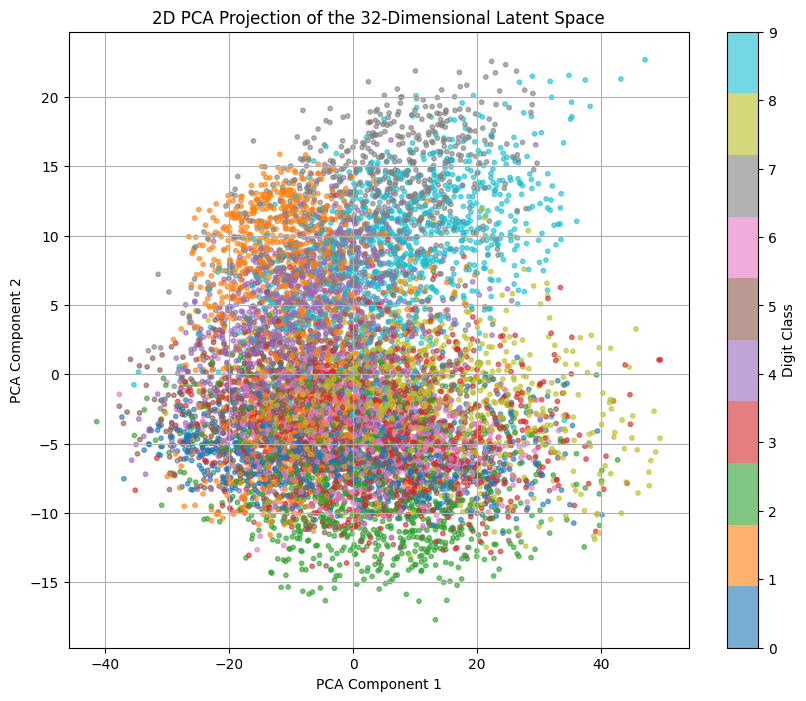

In [9]:
# 6. Visualize the Latent Space using PCA (dimensionality reduction from 32 down to 2)
pca = PCA(n_components=2)
latent_2d = pca.fit_transform(encoded_imgs)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(latent_2d[:, 0], latent_2d[:, 1], c=y_test, cmap='tab10', alpha=0.6, s=10)
plt.colorbar(scatter, label='Digit Class')
plt.title('2D PCA Projection of the 32-Dimensional Latent Space')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.grid(True)
plt.show()